# DE methods walkthrough

Runs `pdata.de` with each test method on the PD test file (`tests/test_pd_prot.txt`, 12 samples). `limma` needs a log-transformed layer; `correct_fdr=True` adds BH-adjusted p-values.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scpviz import pAnnData, utils
from scpviz import plotting as scplt

## Load the test data

In [2]:
pdata = pAnnData.import_data(
    source_type='pd',
    prot_file='../tests/test_pd_prot.txt',
    obs_columns=['sample', 'cellline', 'treatment'],
    fetch_uniprot=False,
)
print(pdata.prot.obs[['cellline', 'treatment']].value_counts())

🧭 [USER] Importing data of type [pd]
--------------------------
Starting import [Proteome Discoverer]

Source file: ../tests/test_pd_prot.txt / None
Number of files: 12
Proteins: 4988

     ⚠️ [WARN] Skipping UniProt gene lookup during import (25 missing). Set fetch_uniprot=True on import, or call pdata.update_missing_genes() later.
ℹ️ Removed 64 empty proteins (all-NaN or all-zero). Proteins: P49448, P53675, Q8IZP2, Q15173, O43402, P40123, O95954, O75382, Q9NYQ6, Q14BN4, ...
     ℹ️ [INFO] Using global q-values for 'prot' significance annotation.

     ✅ [OK] pAnnData object is valid.
     ✅ [OK] Import complete. Use `print(pdata)` to view the object.
--------------------------
cellline  treatment
AS        kd           3
          sc           3
BE        kd           3
          sc           3
Name: count, dtype: int64


## Log-transform (zeros are treated as missing inside `de`)

In [3]:
pdata.log_transform(base=2)
values = [{'cellline': 'BE'}, {'cellline': 'AS'}]

🧭 [USER] Log-transforming [protein] layer: 'X' → 'X_log2'
     🔸 base: 2 log base (pseudocount 1.0)
     ✅ Log transform complete. Results stored in:
       • .prot.layers['X_log2']
       • .prot.X updated
       • .prot.uns['layer_provenance']['X_log2'] updated
     ℹ️ Set protein data to layer X_log2.


## Standard tests: t-test, Mann-Whitney U

In [4]:
res = {}
for method in ['ttest', 'mannwhitneyu']:
    res[method] = pdata.de(values=values, method=method, correct_fdr=True)
res['ttest'].head()

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'cellline': 'BE'}] vs [{'cellline': 'AS'}]
   🔸 Group sizes: 6 vs 6 samples
   🔸 Layer: X (log-transformed)
   🔸 Method: ttest | Fold Change: mean
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] Layer 'X' is log-transformed (log2) — using mean difference for log2FC.
     ℹ️ [INFO] 131 proteins were not comparable (zero or NaN mean in one group).
     ℹ️ [INFO] 144 proteins had <50% valid values in at least one group and were excluded from FDR correction (too sparse for a reliable test); adj_p_value is NaN for these.
     ✅ DE complete. Results stored in:
       • .stats["[{'cellline': 'BE'}] vs [{'cellline': 'AS'}]"]
       • Columns: log2fc, p_value, adj_p_value, significance, etc.
       • Upregulated: 838 | Downregulated: 358 | Not significant: 3597 | Not comparable: 131
🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'cellline': 'BE'}] vs [{'cellline': 'AS

,Genes,[{'cellline': 'BE'}],[{'cellline': 'AS'}],log2fc,p_value,test_statistic,-log10(p_value),significance_score,adj_p_value,-log10(adj_p_value),significance
P07437,TUBB,29.907823,28.880024,1.027799,1.077026e-05,8.081770,4.967774,5.105871,0.000116,3.937089,upregulated
Q96I59,NARS2,21.769307,20.071212,1.698095,9.113936e-07,10.622550,6.040294,10.256992,0.000024,4.624688,upregulated
Q8NI60,COQ8A,20.941838,18.641158,2.300681,4.182449e-07,11.549727,6.378569,14.675051,0.000015,4.838507,upregulated
P35573,AGL,21.690308,20.632055,1.058253,8.048546e-05,6.378776,4.094283,4.332786,0.000510,3.292214,upregulated
Q9Y450,HBS1L,21.398329,19.888880,1.509450,3.996141e-05,6.939828,4.398359,6.639102,0.000305,3.515116,upregulated


## limma (moderated t-test)

The shared prior is printed once and stored in `df.attrs['limma']`.

In [5]:
res['limma'] = pdata.de(values=values, method='limma', correct_fdr=True)
print(res['limma'].attrs['limma'])
res['limma'].head()

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'cellline': 'BE'}] vs [{'cellline': 'AS'}]
   🔸 Group sizes: 6 vs 6 samples
   🔸 Layer: X (log-transformed)
   🔸 Method: limma | Fold Change: mean
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] Layer 'X' is log-transformed (log2) — using mean difference for log2FC.
     ℹ️ [INFO] 131 proteins were not comparable (zero or NaN mean in one group).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 5.99, prior variance = 0.121.
     ✅ DE complete. Results stored in:
       • .stats["[{'cellline': 'BE'}] vs [{'cellline': 'AS'}]"]
       • Columns: log2fc, p_value, adj_p_value, significance, etc.
       • Upregulated: 907 | Downregulated: 405 | Not significant: 3481 | Not comparable: 131
{'s2_prior': 0.12122656786571272, 'df_prior': 5.990529996676351, 'estimator': 'unequal_df'}


,Genes,[{'cellline': 'BE'}],[{'cellline': 'AS'}],log2fc,p_value,test_statistic,-log10(p_value),significance_score,adj_p_value,-log10(adj_p_value),significance
P07437,TUBB,29.907823,28.880024,1.027799,7.788735e-06,6.467755,5.108533,5.250543,5.371425e-05,4.269910,upregulated
Q13015,MLLT11,21.230014,17.297410,3.932604,9.762395e-07,7.658217,6.010444,23.636693,9.976793e-06,5.001009,upregulated
O75717,WDHD1,21.584273,20.484667,1.099605,2.558031e-05,5.831442,4.592094,5.049491,1.391673e-04,3.856463,upregulated
O00762,UBE2C,20.343749,16.767910,3.575839,3.168730e-11,15.913118,10.499115,37.543144,4.339349e-09,8.362575,upregulated
Q99543,DNAJC2,21.851026,20.833060,1.017965,5.485740e-05,5.437740,4.260765,4.337311,2.663946e-04,3.574475,upregulated


## Compare p-values across methods

In [6]:
p = pd.DataFrame({m: df['p_value'] for m, df in res.items()})
print(p.corr(method='spearman').round(3))
print((p < 0.05).sum().rename('raw p < 0.05'))
adj = pd.DataFrame({m: df['adj_p_value'] for m, df in res.items()})
print((adj < 0.05).sum().rename('adj p < 0.05'))

              ttest  mannwhitneyu  limma
ttest         1.000         0.969  0.989
mannwhitneyu  0.969         1.000  0.962
limma         0.989         0.962  1.000
ttest           2740
mannwhitneyu    2279
limma           2813
Name: raw p < 0.05, dtype: int64
ttest           2381
mannwhitneyu    1906
limma           2578
Name: adj p < 0.05, dtype: int64


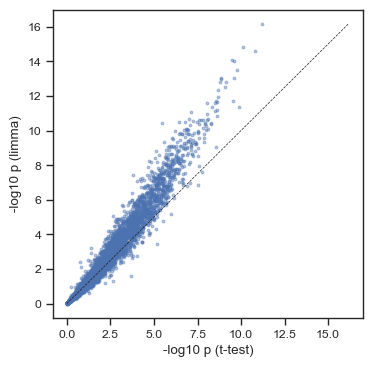

In [7]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(-np.log10(p['ttest']), -np.log10(p['limma']), s=4, alpha=0.4)
lim = [0, np.nanmax(-np.log10(p[['ttest', 'limma']].to_numpy()))]
ax.plot(lim, lim, 'k--', lw=0.5)
ax.set_xlabel('-log10 p (t-test)'); ax.set_ylabel('-log10 p (limma)')
plt.show()

## Wilcoxon (signed-rank)

Paired test: needs equal group sizes with matched samples, so it is only meaningful for paired designs.

In [8]:
try:
    res['wilcoxon'] = pdata.de(values=values, method='wilcoxon')
    print(res['wilcoxon']['p_value'].notna().sum(), 'proteins tested')
except Exception as e:
    print('wilcoxon not applicable here:', e)

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'cellline': 'BE'}] vs [{'cellline': 'AS'}]
   🔸 Group sizes: 6 vs 6 samples
   🔸 Layer: X (log-transformed)
   🔸 Method: wilcoxon | Fold Change: mean
   🔸 P-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] Layer 'X' is log-transformed (log2) — using mean difference for log2FC.
     ℹ️ [INFO] 131 proteins were not comparable (zero or NaN mean in one group).
     ✅ DE complete. Results stored in:
       • .stats["[{'cellline': 'BE'}] vs [{'cellline': 'AS'}]"]
       • Columns: log2fc, p_value, significance, etc.
       • Upregulated: 709 | Downregulated: 284 | Not significant: 3800 | Not comparable: 131
4282 proteins tested


## Volcano plots

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'cellline': 'BE'}] vs [{'cellline': 'AS'}]
   🔸 Group sizes: 6 vs 6 samples
   🔸 Layer: X (log-transformed)
   🔸 Method: ttest | Fold Change: mean
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1
     ℹ️ [INFO] Layer 'X' is log-transformed (log2) — using mean difference for log2FC.
     ℹ️ [INFO] 131 proteins were not comparable (zero or NaN mean in one group).
     ℹ️ [INFO] 144 proteins had <50% valid values in at least one group and were excluded from FDR correction (too sparse for a reliable test); adj_p_value is NaN for these.
     ✅ DE complete. Results stored in:
       • .stats["[{'cellline': 'BE'}] vs [{'cellline': 'AS'}]"]
       • Columns: log2fc, p_value, adj_p_value, significance, etc.
       • Upregulated: 838 | Downregulated: 358 | Not significant: 3597 | Not comparable: 131


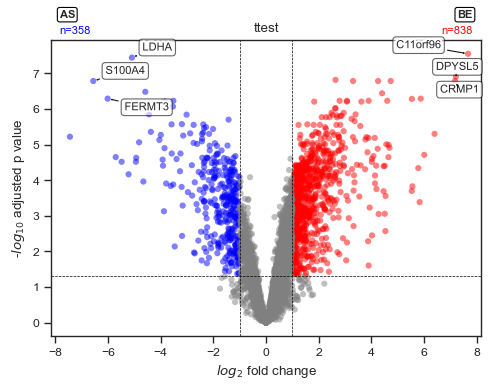

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'cellline': 'BE'}] vs [{'cellline': 'AS'}]
   🔸 Group sizes: 6 vs 6 samples
   🔸 Layer: X (log-transformed)
   🔸 Method: limma | Fold Change: mean
   🔸 Adj p-value threshold: 0.05 | Log2FC threshold: 1
     ℹ️ [INFO] Layer 'X' is log-transformed (log2) — using mean difference for log2FC.
     ℹ️ [INFO] 131 proteins were not comparable (zero or NaN mean in one group).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 5.99, prior variance = 0.121.
     ✅ DE complete. Results stored in:
       • .stats["[{'cellline': 'BE'}] vs [{'cellline': 'AS'}]"]
       • Columns: log2fc, p_value, adj_p_value, significance, etc.
       • Upregulated: 907 | Downregulated: 405 | Not significant: 3481 | Not comparable: 131


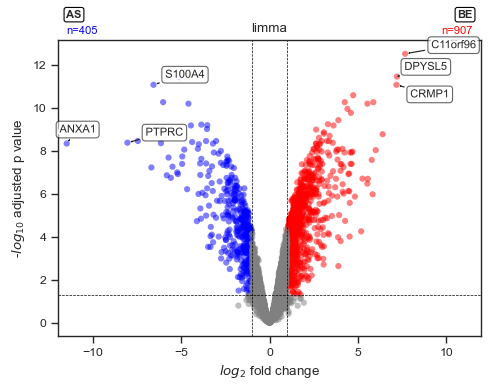

In [11]:
for m in ['ttest', 'limma']:
    fig, ax = plt.subplots(1, 1, figsize=(5, 4))
    scplt.plot_volcano(ax, pdata, values=values, method=m, correct_fdr=True, label=3)
    plt.title(m)
    plt.tight_layout(); plt.show()


## Standalone on an AnnData: `utils.de_adata`

`data_is_log=True` is required for limma; `log2fc` is then the fitted group difference.

In [12]:
df = utils.de_adata(
    pdata.prot, values=values, method='limma', data_is_log=True,
    layer='X_log2', correct_fdr=True,
)
df.head()

     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 5.99, prior variance = 0.121.


,Genes,[{'cellline': 'BE'}],[{'cellline': 'AS'}],log2fc,p_value,test_statistic,-log10(p_value),significance_score,adj_p_value,-log10(adj_p_value),significance
P07437,TUBB,29.907823,28.880024,1.027799,0.000008,6.467755,5.108533,5.250543,0.000054,4.269910,upregulated
P78527,PRKDC,28.045563,27.869791,0.175772,0.285921,1.104021,0.543754,0.095577,0.364764,0.437988,not significant
Q13813,SPTAN1,27.621504,27.358474,0.263030,0.137911,1.561781,0.860401,0.226311,0.197552,0.704320,not significant
Q13813-3,SPTAN1,18.995995,17.930248,1.065747,0.000314,4.572079,3.503452,3.733795,0.001149,2.939784,upregulated
P68371,TUBB4B,24.499158,24.546454,-0.047296,0.801543,-0.255567,0.096073,-0.004544,0.844722,0.073286,not significant


## limma details

The shared prior (estimator, prior df, prior variance) is stored on the result; `test_statistic` is the moderated t.

In [13]:
lim = pdata.de(values=values, method='limma')
print(lim.attrs['limma'])
lim[['log2fc', 'test_statistic', 'p_value']].describe().round(3)

🧭 [USER] Running differential expression [protein]
   🔸 Comparing groups: [{'cellline': 'BE'}] vs [{'cellline': 'AS'}]
   🔸 Group sizes: 6 vs 6 samples
   🔸 Layer: X (log-transformed)
   🔸 Method: limma | Fold Change: mean
   🔸 P-value threshold: 0.05 | Log2FC threshold: 1.0
     ℹ️ [INFO] Layer 'X' is log-transformed (log2) — using mean difference for log2FC.
     ℹ️ [INFO] 131 proteins were not comparable (zero or NaN mean in one group).
     ℹ️ [INFO] limma (unequal_df prior estimator): prior df = 5.99, prior variance = 0.121.
     ✅ DE complete. Results stored in:
       • .stats["[{'cellline': 'BE'}] vs [{'cellline': 'AS'}]"]
       • Columns: log2fc, p_value, significance, etc.
       • Upregulated: 915 | Downregulated: 410 | Not significant: 3468 | Not comparable: 131
{'s2_prior': 0.12122656786571272, 'df_prior': 5.990529996676351, 'estimator': 'unequal_df'}


,log2fc,test_statistic,p_value
count,4793.000,4793.000,4793.000
mean,0.300,1.416,0.164
std,1.163,4.727,0.263
min,-11.467,-29.396,0.000
25%,-0.199,-0.883,0.000
50%,0.312,1.505,0.016
75%,0.813,3.809,0.218
max,7.666,36.946,0.998
